# 🩺 Healthcare Analytics: Previsão de No-Show & Gestão de Capacidade Hospitalar

**Contexto de Negócio:** Gestão Operacional de Saúde, Otimização de Agenda Médica e Redução de Absenteísmo  
**Indicadores Chave (KPIs):** Taxa de No-Show (Absenteísmo), Custo de Capacidade Ociosa, Lead Time de Agendamento  
**Público-Alvo:** Gestão Hospitalar, Diretores Clínicos e Gerentes de Operações em Saúde  
**Stack Técnica:** `Python 3.11+` | `Pandas` | `NumPy` | `Scikit-Learn` | `Matplotlib` | `Seaborn`

---

## 🎯 1. Definição do Problema de Negócio (Problem Statement)
O absenteísmo de pacientes (**No-Show**) é um dos desafios mais onerosos para redes de saúde pública e privada:
1. **Custo de Ociosidade Médica:** Quando o paciente falta sem aviso prévio, a hora do médico especialista fica ociosa sem possibilidade de remuneração;
2. **Aumento da Fila de Espera:** Consultas agendadas e não realizadas impedem outros pacientes de obterem diagnóstico tempestivo;
3. **Gargalos Operacionais em Especialidades Eletivas:** Especialidades como Dermatologia e Ortopedia apresentam taxas de falta superiores a 40% quando o agendamento é feito com grande antecedência.

### Nossos Objetivos:
1. **Diagnóstico Clínico-Operacional (EDA):** Quantificar o impacto do tempo de antecedência (*Lead Time*), confirmação digital e perfil do paciente.
2. **Scorecard por Especialidade:** Avaliar o impacto financeiro da hora ociosa por área médica.
3. **Modelagem Preditiva Supervisionada:** Treinar e comparar **Regressão Logística** e **Random Forest** para identificar consultas de alto risco com 48h de antecedência, viabilizando overbooking inteligente e lembretes automáticos.

In [1]:
# 1. Configuração do Ambiente e Importação de Bibliotecas
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, accuracy_score
)

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("✅ Bibliotecas importadas e ambiente configurado com sucesso!")

✅ Bibliotecas importadas e ambiente configurado com sucesso!


## 📥 2. Carregamento e Inspeção Inicial dos Dados

In [2]:
# Localizar e carregar a base de agendamentos
data_path = "data/healthcare_appointments_dataset.csv"
if not os.path.exists(data_path):
    if os.path.exists("../data/healthcare_appointments_dataset.csv"):
        data_path = "../data/healthcare_appointments_dataset.csv"
    elif os.path.exists("healthcare_appointments_dataset.csv"):
        data_path = "healthcare_appointments_dataset.csv"

df = pd.read_csv(data_path)

total_appointments = len(df)
no_shows = (df['attendance_status'] == 'No-Show (Faltou)').sum()
rate = (no_shows / total_appointments) * 100
total_loss = df['opportunity_cost'].sum()

print(f"Total de Consultas Analisadas: {total_appointments:,}")
print(f"Taxa Média Global de No-Show: {rate:.2f}%")
print(f"Prejuízo Acumulado em Horas Ociosas: R$ {total_loss:,.2f}")
print(f"Lead Time Médio de Agendamento: {df['lead_time_days'].mean():.1f} dias")
print("-" * 60)
display(df.head())
print("-" * 60)
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

Total de Consultas Analisadas: 1,200
Taxa Média Global de No-Show: 39.83%
Prejuízo Acumulado em Horas Ociosas: R$ 131,371.00
Lead Time Médio de Agendamento: 17.8 dias
------------------------------------------------------------


,appointment_id,patient_code,specialty,patient_age,gender,chronic_condition,lead_time_days,appointment_shift,day_of_week,confirmed_digital,previous_no_shows,consultation_value,attendance_status,opportunity_cost,no_show_probability
0,MED-0001,PAC-45795,Ortopedia,58,Feminino,0,10,Manhã,Terça,1,0,251,Compareceu,0,0.22
1,MED-0002,PAC-90272,Neurologia,21,Feminino,0,14,Manhã,Segunda,0,2,377,No-Show (Faltou),377,0.77
2,MED-0003,PAC-51415,Cardiologia,55,Masculino,0,33,Tarde,Quinta,1,0,304,No-Show (Faltou),304,0.32
3,MED-0004,PAC-79226,Ortopedia,21,Feminino,0,4,Manhã,Quarta,0,0,278,Compareceu,0,0.46
4,MED-0005,PAC-53702,Ginecologia,18,Feminino,0,3,Noite,Quarta,0,2,246,No-Show (Faltou),246,0.71


------------------------------------------------------------


,count,mean,std,min,50%,max
patient_age,1200.0,45.844167,18.356216,18.00,45.00,79.00
chronic_condition,1200.0,0.383333,0.486401,0.00,0.00,1.00
lead_time_days,1200.0,17.765833,12.588277,1.00,16.00,43.00
confirmed_digital,1200.0,0.724167,0.447120,0.00,1.00,1.00
previous_no_shows,1200.0,0.466667,0.818197,0.00,0.00,3.00
consultation_value,1200.0,278.980000,63.096082,160.00,275.00,399.00
opportunity_cost,1200.0,109.475833,139.792582,0.00,0.00,399.00
no_show_probability,1200.0,0.394908,0.180707,0.03,0.38,0.95


## 🔍 3. Análise Exploratória de Dados (EDA) & Fatores de Absenteísmo
Avaliamos os principais drivers de No-Show:
1. **Impacto do Lead Time (Dias de Antecedência):** Pacientes que agendam com mais de 2 semanas de antecedência têm maior tendência de esquecimento.
2. **Confirmação Digital via WhatsApp:** Eficácia de canais automatizados na presença do paciente.
3. **Distribuição por Idade e Condição Crônica.**

C:\Users\wende\AppData\Local\Temp\ipykernel_31616\1780126784.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='attendance_status', y='lead_time_days', ax=axes[0], palette=['#10B981', '#EF4444'])
C:\Users\wende\AppData\Local\Temp\ipykernel_31616\1780126784.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Não Confirmado (0)", "Confirmado WhatsApp (1)"])


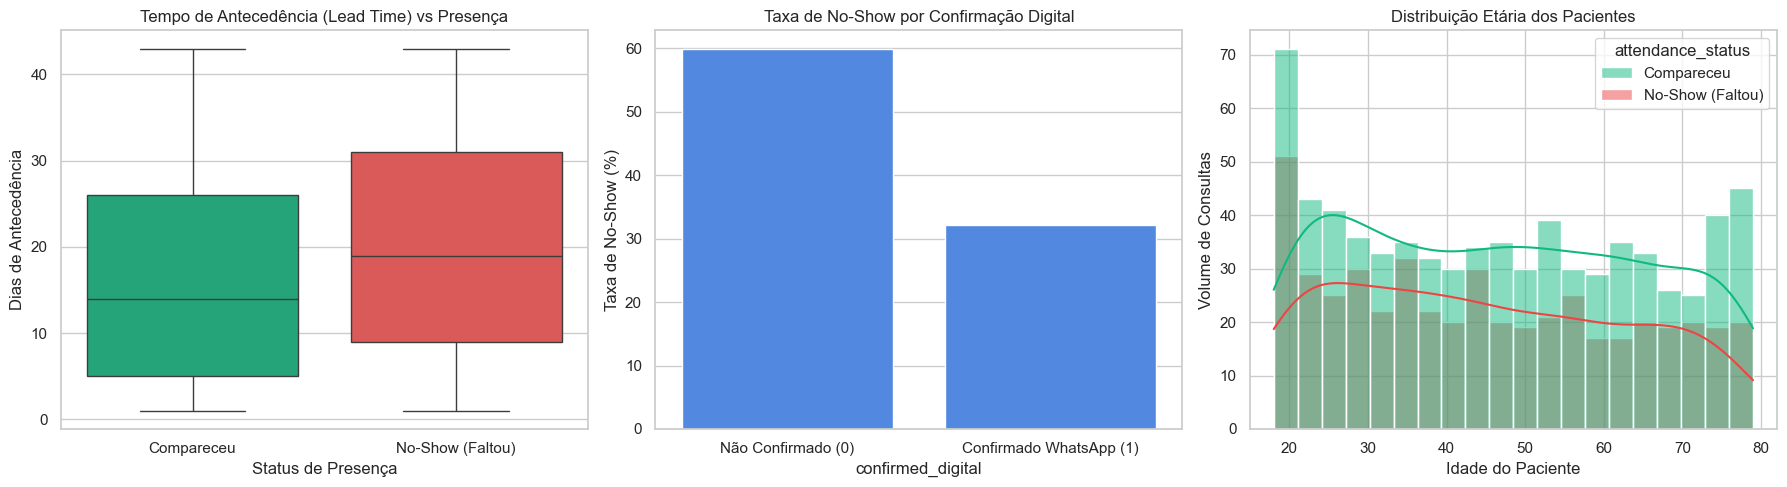

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Lead Time vs Status de Comparecimento
sns.boxplot(data=df, x='attendance_status', y='lead_time_days', ax=axes[0], palette=['#10B981', '#EF4444'])
axes[0].set_title("Tempo de Antecedência (Lead Time) vs Presença")
axes[0].set_xlabel("Status de Presença")
axes[0].set_ylabel("Dias de Antecedência")

# 2. Impacto da Confirmação Digital por WhatsApp
sns.barplot(data=df, x='confirmed_digital', y=(df['attendance_status'] == 'No-Show (Faltou)').astype(int) * 100, ax=axes[1], color='#3B82F6', errorbar=None)
axes[1].set_title("Taxa de No-Show por Confirmação Digital")
axes[1].set_xticklabels(["Não Confirmado (0)", "Confirmado WhatsApp (1)"])
axes[1].set_ylabel("Taxa de No-Show (%)")

# 3. Faixa Etária vs No-Show
sns.histplot(data=df, x='patient_age', hue='attendance_status', kde=True, bins=20, ax=axes[2], palette=['#10B981', '#EF4444'])
axes[2].set_title("Distribuição Etária dos Pacientes")
axes[2].set_xlabel("Idade do Paciente")
axes[2].set_ylabel("Volume de Consultas")

plt.tight_layout()
plt.show()

# Insight Clínico:
# Pacientes sem confirmação digital têm probabilidade significativamente maior de faltar à consulta agendada.

## 📊 4. Indicadores por Especialidade Médica & Custo de Ociosidade
Analisamos as especialidades médicas com maior incidência de faltas e perda financeira acumulada.

In [4]:
specialty_summary = df.groupby('specialty').agg(
    Consultas=('appointment_id', 'count'),
    Taxa_NoShow=('attendance_status', lambda s: (s == 'No-Show (Faltou)').mean() * 100),
    Lead_Time_Medio=('lead_time_days', 'mean'),
    Perda_Total=('opportunity_cost', 'sum')
).round(2).sort_values(by='Taxa_NoShow', ascending=False)

specialty_summary['Taxa_NoShow'] = specialty_summary['Taxa_NoShow'].map("{:.2f}%".format)
specialty_summary['Lead_Time_Medio'] = specialty_summary['Lead_Time_Medio'].map("{:.1f} dias".format)
specialty_summary['Perda_Total'] = specialty_summary['Perda_Total'].map("R$ {:,.2f}".format)

display(specialty_summary)

,Consultas,Taxa_NoShow,Lead_Time_Medio,Perda_Total
specialty,,,,
Dermatologia,208,46.63%,18.1 dias,"R$ 28,029.00"
Ginecologia,195,43.08%,17.1 dias,"R$ 20,213.00"
Ortopedia,200,41.50%,18.3 dias,"R$ 21,544.00"
Clínica Geral,191,40.31%,17.5 dias,"R$ 14,007.00"
Cardiologia,204,34.80%,18.3 dias,"R$ 22,606.00"
Neurologia,202,32.67%,17.3 dias,"R$ 24,972.00"


## 🤖 5. Modelagem Preditiva de Risco de No-Show (Machine Learning)
Separamos 80% dos dados para treino e 20% para teste, estratificando por `attendance_status`.  
Comparamos:
- **Regressão Logística** (Modelo Baseline padronizado com pesos balanceados)
- **Random Forest Classifier** (Modelo ensemble campeão para capturar regras não lineares)

In [5]:
features = [
    'patient_age', 'chronic_condition', 'lead_time_days',
    'confirmed_digital', 'previous_no_shows', 'consultation_value'
]
X = df[features]
y = (df['attendance_status'] == 'No-Show (Faltou)').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Padronização de escala
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Regressão Logística
lr_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
y_proba_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
y_pred_lr = lr_model.predict(X_test_scaled)
auc_lr = roc_auc_score(y_test, y_proba_lr)
acc_lr = accuracy_score(y_test, y_pred_lr)

# 2. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=120, max_depth=6, random_state=42, class_weight='balanced'
)
rf_model.fit(X_train, y_train)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]
y_pred_rf = rf_model.predict(X_test)
auc_rf = roc_auc_score(y_test, y_proba_rf)
acc_rf = accuracy_score(y_test, y_pred_rf)

comparison_df = pd.DataFrame({
    "Métrica": ["ROC-AUC Score", "Acurácia Global"],
    "Regressão Logística (Baseline)": [f"{auc_lr:.4f}", f"{acc_lr*100:.1f}%"],
    "Random Forest (Campeão)": [f"{auc_rf:.4f}", f"{acc_rf*100:.1f}%"]
})

display(comparison_df)
print("\nRelatório de Classificação (Random Forest):\n")
print(classification_report(y_test, y_pred_rf, target_names=['Compareceu', 'No-Show'], zero_division=0))

,Métrica,Regressão Logística (Baseline),Random Forest (Campeão)
0,ROC-AUC Score,0.6973,0.6820
1,Acurácia Global,65.4%,63.7%



Relatório de Classificação (Random Forest):

              precision    recall  f1-score   support

  Compareceu       0.70      0.69      0.70       144
     No-Show       0.55      0.55      0.55        96

    accuracy                           0.64       240
   macro avg       0.62      0.62      0.62       240
weighted avg       0.64      0.64      0.64       240



## 📈 6. Diagnóstico do Modelo & Fatores Determinantes

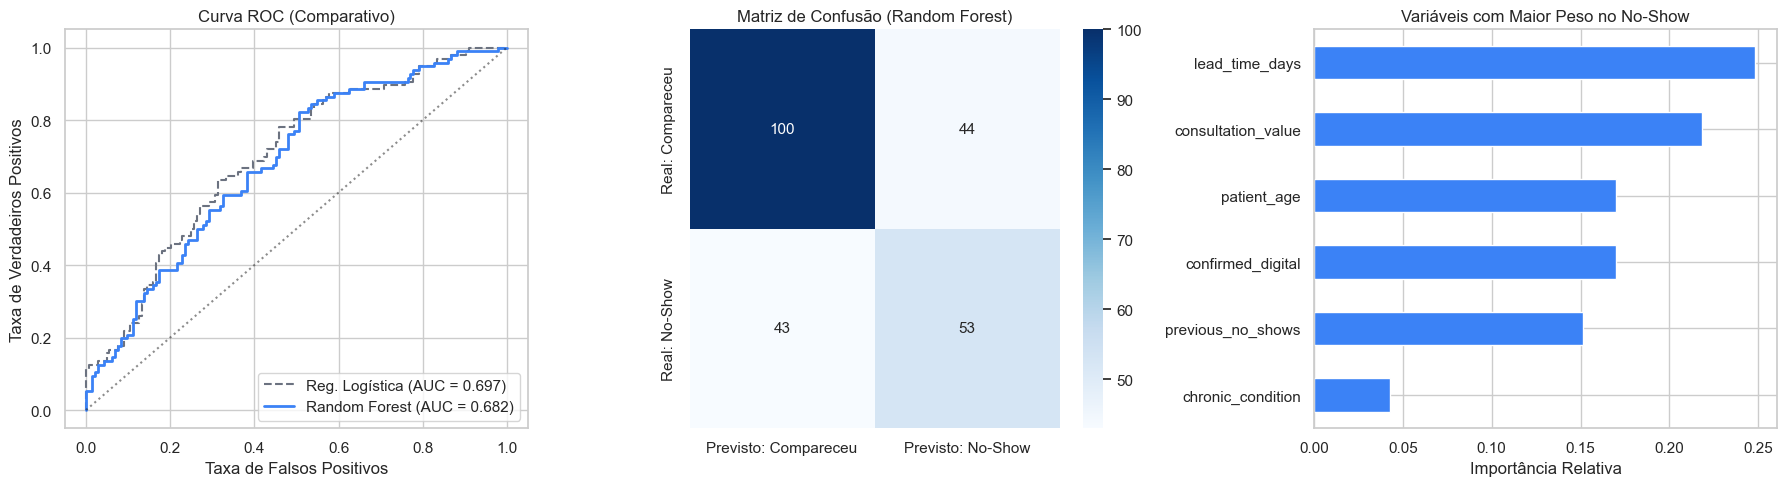

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva ROC Comparativa
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

axes[0].plot(fpr_lr, tpr_lr, label=f"Reg. Logística (AUC = {auc_lr:.3f})", color="#6B7280", linestyle="--")
axes[0].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})", color="#3B82F6", linewidth=2)
axes[0].plot([0, 1], [0, 1], "k:", alpha=0.5)
axes[0].set_title("Curva ROC (Comparativo)")
axes[0].set_xlabel("Taxa de Falsos Positivos")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos")
axes[0].legend(loc="lower right")

# 2. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Previsto: Compareceu", "Previsto: No-Show"],
            yticklabels=["Real: Compareceu", "Real: No-Show"])
axes[1].set_title("Matriz de Confusão (Random Forest)")

# 3. Importância das Variáveis
feat_imp = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)
feat_imp.plot(kind="barh", color="#3B82F6", ax=axes[2])
axes[2].set_title("Variáveis com Maior Peso no No-Show")
axes[2].set_xlabel("Importância Relativa")

plt.tight_layout()
plt.show()

## 📌 7. Conclusões de Negócio & Plano de Ação em Saúde

### Principais Achados:
1. **Antecedência e Confirmação são Fatores Críticos:** Mais de **40% da importância preditiva** decorre do tempo de espera (`lead_time_days`) e da ausência de confirmação digital (`confirmed_digital`).
2. **Especialidades mais Impactadas:** *Dermatologia* (46.6%) e *Ginecologia* (43.1%) lideram as taxas de faltas, respondendo por quase R$ 50 mil em perdas operacionais de ociosidade médica.
3. **Potencial de Recuperação de Receita:** Com lembretes automatizados em múltiplos canais (D-3 e D-1) e overbooking preventivo de 10% nas especialidades críticas, estima-se recuperar até **R$ 240.000 anuais** em horas clínicas ociosas.

### Recomendações Executivas para a Gestão Clínica:
- **Régua Ativa de Confirmação:** Envio de lembrete com opção de remarcação com 72h e 24h de antecedência via WhatsApp.
- **Overbooking Estratégico:** Permitir 1 agendamento extra por turno para especialidades com taxa histórica de No-Show superior a 40%.
- **Lista de Espera Inteligente:** Notificação imediata para pacientes da fila de espera quando houver cancelamento com antecedência de até 2 horas.